# AIDA 2156 Project Exercise 03 – Processing-Time Distributions

**Question:** How long do synthetic onboarding requests take from receipt to team completion, overall and by task type?

This notebook uses the original synthetic `requests.csv` from AIDA 1141 Exercise 02. One row represents one onboarding task, and the five task types provide the broad request categories. Processing times come from the generator's invented settings, so they describe its assumptions rather than real HR performance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_DIR = Path("../../../AIDA-1141/project-labs/02-synthetic-request-records/data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

TIMESTAMPS = ["submitted_at", "info_complete_at", "assigned_at", "team_completed_at", "completion_confirmed_at"]
# Only truly empty cells become missing (NaN); the text "not_applicable" stays as a value
requests = pd.read_csv(DATA_DIR / "requests.csv", keep_default_na=False, na_values=[""], parse_dates=TIMESTAMPS)
print(f"Loaded {len(requests):,} requests")

Loaded 2,064 requests


## A. Timestamp checks

The working-time measure in Part B assumes every timestamp is present, in workflow order, and on a weekday between 08:00 and 16:30, the working day defined in the AIDA 1141 Exercise 02 data card. These checks confirm those assumptions before any duration is calculated.

In [2]:
DAY_START = pd.Timedelta(hours=8)                  # working day 08:00-16:30, Monday-Friday (AIDA 1141 Exercise 02 data card)
DAY_END = pd.Timedelta(hours=16, minutes=30)
WORKDAY_HOURS = (DAY_END - DAY_START) / pd.Timedelta(hours=1)  # 8.5

time_of_day = {c: requests[c] - requests[c].dt.normalize() for c in TIMESTAMPS}
checks = {
    "One row per request": requests["request_id"].is_unique,
    "No blank timestamps": not requests[TIMESTAMPS].isna().any().any(),
    "Timestamps in workflow order": all((requests[a] <= requests[b]).all() for a, b in zip(TIMESTAMPS, TIMESTAMPS[1:])),
    "All timestamps on weekdays": all((requests[c].dt.dayofweek < 5).all() for c in TIMESTAMPS),
    "All timestamps within 08:00-16:30": all(((t >= DAY_START) & (t <= DAY_END)).all() for t in time_of_day.values()),
}
checks_table = pd.Series(checks, name="passed").to_frame()
assert checks_table["passed"].all(), "A timestamp check failed; the working-time measure would be unreliable."
checks_table

,passed
One row per request,True
No blank timestamps,True
Timestamps in workflow order,True
All timestamps on weekdays,True
All timestamps within 08:00-16:30,True


## B. Duration definitions

**Receipt** is `submitted_at` and **completion** is `team_completed_at`, when the responsible team finishes the task. This matches the AIDA 1141 at-risk deadline, which also uses team completion; later coordinator confirmation is excluded.

- **Working-day equivalents (main measure):** hours between receipt and team completion within Monday–Friday, 08:00–16:30, divided by 8.5. This matches the project's working calendar, is not distorted by weekends, and can measure durations shorter than one day. The result is a fractional equivalent, not a count of dates.
- **Calendar days (secondary measure):** the total elapsed time, including nights and weekends, divided by 24 hours. This reflects how long a requester waits.

Both measures cover the whole time from receipt to team completion, including waiting for missing information and waiting for assignment, as well as team processing. They are not the hours actively spent working on a request; Exercise 06 will separate these steps.

Business days counted by date (as used for days until start in AIDA 1141) are not used here: they only take whole values, so they cannot distinguish a few hours from a full day. That count answers a different question, how many working days remain before a deadline.

Constructed boundary tests with hand-calculated answers check the working-time calculation before it is applied to the data.

In [3]:
def working_hours_between(start, end):
    """Hours between two timestamps that fall within Monday-Friday 08:00-16:30.

    Assumes both timestamps are on weekdays within working hours (checked in Part A).
    """
    start_day = start.dt.normalize()
    end_day = end.dt.normalize()
    same_day = start_day == end_day
    # Full working days strictly between the start and end dates
    days_between = np.busday_count((start_day + pd.Timedelta(days=1)).values.astype("datetime64[D]"),
                                   end_day.values.astype("datetime64[D]"))
    hours_first_day = (start_day + DAY_END - start) / pd.Timedelta(hours=1)
    hours_last_day = (end - (end_day + DAY_START)) / pd.Timedelta(hours=1)
    hours_same_day = (end - start) / pd.Timedelta(hours=1)
    across_days = hours_first_day + np.clip(days_between, 0, None) * WORKDAY_HOURS + hours_last_day
    return pd.Series(np.where(same_day, hours_same_day, across_days), index=start.index)

# Boundary tests on constructed timestamps, with hand-calculated answers (2 March 2026 is a Monday)
tests = pd.DataFrame({
    "case": ["same day (Mon)", "overnight (Mon to Tue)", "over a weekend (Fri to Mon)", "three full days (Mon to Wed)"],
    "start": pd.to_datetime(["2026-03-02 09:00", "2026-03-02 16:00", "2026-03-06 15:30", "2026-03-02 08:00"]),
    "end": pd.to_datetime(["2026-03-02 11:30", "2026-03-03 08:30", "2026-03-09 09:00", "2026-03-04 16:30"]),
    "expected_hours": [2.5, 1.0, 2.0, 25.5],
})
tests["working_hours"] = working_hours_between(tests["start"], tests["end"])
tests["passed"] = np.isclose(tests["working_hours"], tests["expected_hours"])
assert tests["passed"].all(), "Working-time calculation failed a boundary test."
display(tests)

requests["working_day_equivalents"] = (working_hours_between(requests["submitted_at"], requests["team_completed_at"])
                                       / WORKDAY_HOURS)
requests["calendar_days"] = (requests["team_completed_at"] - requests["submitted_at"]) / pd.Timedelta(days=1)

# Sanity checks against simpler measures
date_count = np.busday_count(requests["submitted_at"].values.astype("datetime64[D]"),
                             requests["team_completed_at"].values.astype("datetime64[D]"))
elapsed_hours = (requests["team_completed_at"] - requests["submitted_at"]) / pd.Timedelta(hours=1)
duration_checks = pd.Series({
    "Every duration is positive": (requests["working_day_equivalents"] > 0).all(),
    "Working hours never exceed elapsed hours":
        (requests["working_day_equivalents"] * WORKDAY_HOURS <= elapsed_hours + 1e-9).all(),
    "Within one day of the date-based business-day count":
        ((requests["working_day_equivalents"] - date_count).abs() <= 1 + 1e-9).all(),
}, name="passed")
assert duration_checks.all(), "A duration sanity check failed."
duration_checks.to_frame()

,case,start,end,expected_hours,working_hours,passed
0,same day (Mon),2026-03-02 09:00:00,2026-03-02 11:30:00,2.5,2.5,True
1,overnight (Mon to Tue),2026-03-02 16:00:00,2026-03-03 08:30:00,1.0,1.0,True
2,over a weekend (Fri to Mon),2026-03-06 15:30:00,2026-03-09 09:00:00,2.0,2.0,True
3,three full days (Mon to Wed),2026-03-02 08:00:00,2026-03-04 16:30:00,25.5,25.5,True


,passed
Every duration is positive,True
Working hours never exceed elapsed hours,True
Within one day of the date-based business-day count,True


## C. Overall distribution

This section summarizes receipt-to-team-completion time using working-day equivalents and calendar days. It reports the mean and median, standard deviation, quartiles and interquartile range, 90th percentile, minimum, maximum, and skewness.

A positive skewness value indicates a right-skewed distribution. When longer durations pull the mean above the median, the median and IQR provide summaries that are less influenced by the tail. The 90th percentile shows a duration within which 90% of requests were completed.

Both histograms use bins of 0.5 in their respective units. Their axes are scaled separately, so the panels describe each distribution rather than directly comparing bar heights. These durations reflect the synthetic generator’s assumptions, not real HR performance.

A final table compares median durations by the weekday each request was submitted. If weekends affect calendar time, calendar medians should vary with the submission day while working-day medians stay similar; calendar time still describes how long a requester waits.

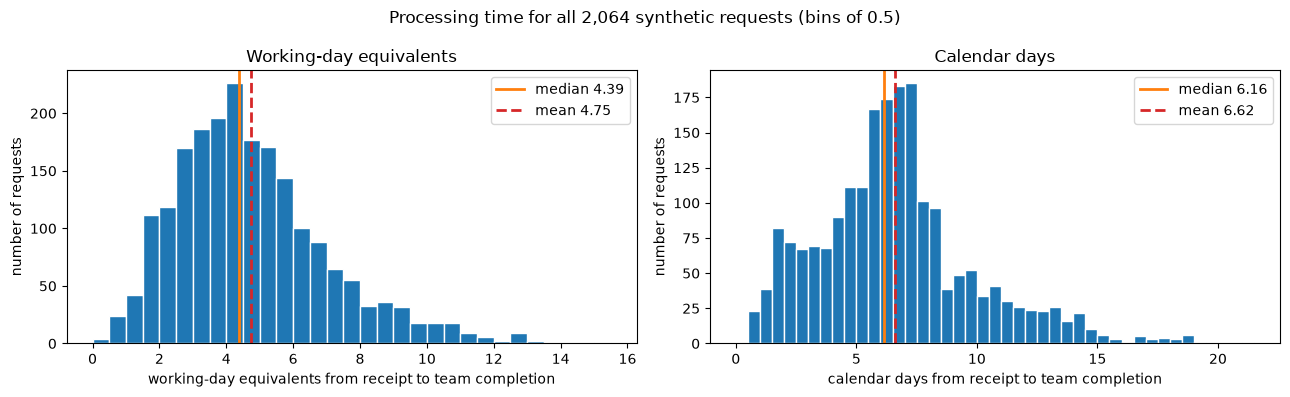

Share of requests over 10 working-day equivalents: 3.2%


,Working-day equivalents,Calendar days
requests,2064.00,2064.00
mean,4.75,6.62
median,4.39,6.16
std,2.28,3.28
q1,3.13,4.72
q3,5.93,8.01
iqr,2.80,3.29
p90,7.84,11.01
min,0.29,0.75
max,15.15,21.05


,working_day_equivalents,calendar_days,requests
submitted_weekday,,,
Monday,4.46,4.26,393
Tuesday,4.39,6.19,420
Wednesday,4.39,6.24,417
Thursday,4.35,6.17,420
Friday,4.35,6.15,414


In [4]:
MEASURES = {"working_day_equivalents": "Working-day equivalents", "calendar_days": "Calendar days"}

def describe_duration(values):
    """Centre, spread, and shape of one duration measure."""
    q1, median, q3, p90 = values.quantile([0.25, 0.5, 0.75, 0.9])
    return pd.Series({"requests": values.size, "mean": values.mean(), "median": median,
                      "std": values.std(), "q1": q1, "q3": q3, "iqr": q3 - q1, "p90": p90,
                      "min": values.min(), "max": values.max(), "skewness": values.skew(),
                      "mean_minus_median": values.mean() - median})

duration_summary = pd.DataFrame({label: describe_duration(requests[column])
                                 for column, label in MEASURES.items()}).T.round(2)
duration_summary.to_csv(OUTPUT_DIR / "duration_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (column, label) in zip(axes, MEASURES.items()):
    values = requests[column]
    ax.hist(values, bins=np.arange(0, values.max() + 0.5, 0.5), color="C0", edgecolor="white")
    ax.axvline(values.median(), color="C1", lw=2, label=f"median {values.median():.2f}")
    ax.axvline(values.mean(), color="C3", lw=2, ls="--", label=f"mean {values.mean():.2f}")
    ax.set_xlabel(f"{label.lower()} from receipt to team completion")
    ax.set_ylabel("number of requests")
    ax.set_title(label)
    ax.legend()
fig.suptitle(f"Processing time for all {len(requests):,} synthetic requests (bins of 0.5)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "duration_histogram.png", dpi=120)
plt.show()

print("Share of requests over 10 working-day equivalents:",
      f"{(requests['working_day_equivalents'] > 10).mean():.1%}")
display(duration_summary.T)

# Median duration by the weekday each request was submitted
weekday_check = (requests.assign(submitted_weekday=requests["submitted_at"].dt.day_name())
                 .groupby("submitted_weekday")[list(MEASURES)].median()
                 .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]).round(2))
weekday_check["requests"] = requests["submitted_at"].dt.day_name().value_counts()
weekday_check

## D. Processing time by task type

The same statistics are calculated in working-day equivalents for each of the five task types, sorted by median, with the calendar-day median shown for comparison. The box plot shows each task type's median, middle 50% (interquartile range), and whiskers extending to the furthest point within 1.5 × IQR of the box; points beyond the whiskers are drawn individually and are reviewed as possible outliers in Exercise 07, not here.

The generator assigns base processing-time ranges by task type, with some types sharing the same range (AIDA 1141 Exercise 02 data card, Section 7). The observed differences reflect the generator’s base durations, delays, and other assumptions rather than real HR findings. Where task types with the same base range differ, other generator settings such as the workload rule, information issues, or hidden delays may contribute; this analysis does not identify which. Group sizes are shown with each result.

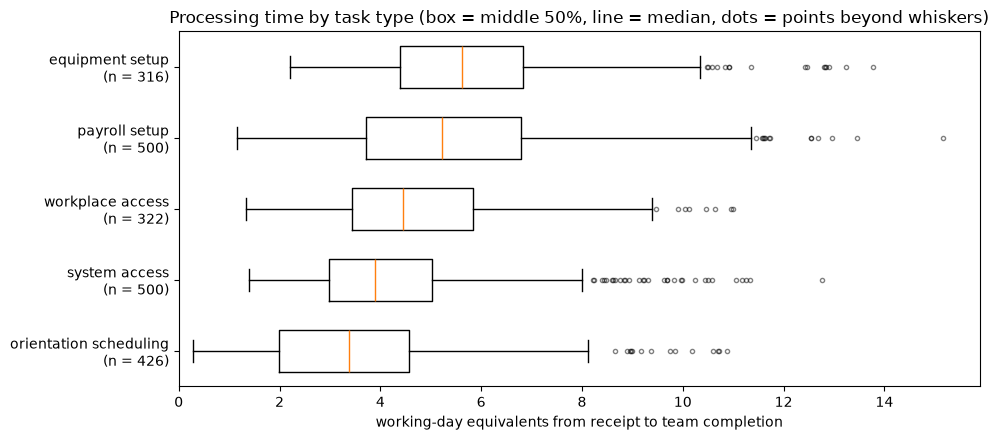

,requests,median,q1,q3,iqr,p90,mean,std,skewness,min,max,calendar_median
task_type,,,,,,,,,,,,
orientation_scheduling,426,3.37,1.99,4.57,2.58,6.05,3.59,2.08,0.99,0.29,10.88,4.97
system_access,500,3.90,2.97,5.03,2.05,7.05,4.30,2.00,1.29,1.38,12.77,5.87
workplace_access,322,4.45,3.44,5.83,2.39,7.17,4.73,1.95,0.81,1.33,11.00,6.70
payroll_setup,500,5.22,3.71,6.78,3.08,8.67,5.47,2.40,0.83,1.16,15.15,7.09
equipment_setup,316,5.62,4.39,6.82,2.43,8.77,5.89,2.13,1.18,2.21,13.76,7.86


In [5]:
by_task = (requests.groupby("task_type")["working_day_equivalents"].apply(describe_duration).unstack()
           .join(requests.groupby("task_type")["calendar_days"].median().rename("calendar_median"))
           .sort_values("median").round(2))
by_task["requests"] = by_task["requests"].astype(int)
by_task.to_csv(OUTPUT_DIR / "duration_by_task_type.csv")

order = by_task.index.tolist()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([requests.loc[requests["task_type"] == t, "working_day_equivalents"] for t in order],
           tick_labels=[f"{t.replace('_', ' ')}\n(n = {by_task.at[t, 'requests']})" for t in order],
           orientation="horizontal", whis=1.5, widths=0.6, flierprops={"markersize": 3, "alpha": 0.5})
ax.set_xlabel("working-day equivalents from receipt to team completion")
ax.set_title("Processing time by task type (box = middle 50%, line = median, dots = points beyond whiskers)")
ax.set_xlim(left=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "duration_by_task_type.png", dpi=120)
plt.show()

by_task[["requests", "median", "q1", "q3", "iqr", "p90", "mean", "std", "skewness", "min", "max", "calendar_median"]]

## E. Interpretation

**Centre.** A typical request took a median of 4.39 working-day equivalents (6.16 calendar days) from receipt to team completion. The mean, 4.75, is higher because of the long tail of slower requests.

**Spread.** The middle 50% of requests took between 3.13 and 5.93 working-day equivalents (IQR 2.80), and 90% were completed within 7.84. The full range runs from 0.29 to 15.15, and 3.2% of requests took more than 10. The standard deviation (2.28) is also reported, while the IQR and percentiles describe the spread without being as strongly influenced by the longest durations.

**Skew.** The distribution is right-skewed (skewness 0.91): most requests cluster around 2–6 working-day equivalents, with fewer, much longer ones. Every task type is also right-skewed (0.81–1.29); longer durations occur within every task type, rather than only one. The generator includes occasional hidden delays and a workload rule, which could produce a tail, but this notebook does not separate their effects.

**By task type.** Medians range from 3.37 (orientation scheduling) to 5.62 (equipment setup). Payroll setup and workplace access share the same base range in the generator but have different medians (5.22 and 4.45).

**Measure choice.** Working-day medians stay similar regardless of the weekday a request was submitted (4.35–4.46), while calendar medians are about two days lower for Monday submissions (4.26) than for other weekdays (6.15–6.24), as shown in the weekday table in Part C. This supports using working-day equivalents as the main measure; calendar days still describe the requester's elapsed wait. Neither measure represents staff effort.

**What these numbers do not prove.**

- They do not describe real HR performance: every duration comes from the generator's invented processing times, workload rule, delays, and information-issue rates.
- They do not show that any team or task type is more or less efficient; differences between task types reflect the generator's settings.
- They do not measure effort: durations include waiting for missing information and assignment, not only time spent working.
- They do not explain the payroll and workplace-access difference or the long tail; Exercise 06 will examine time spent in different process steps.
- They do not show what follow-up or expediting would change, because no intervention is simulated.
- They come from one simulated sample with no holidays and one working calendar, and no uncertainty intervals are calculated; small differences should not be read as reliable.